# Домашнее задание. Занятие 11. Мидтерм, этап 1: от сырого файла к чистой таблице

**DataGroup. Курс AI Engineering. Неделя 6**

Это тетрадь вашего мидтерм-проекта. На этапе 1 (домашка занятия 11) вы заполняете разделы 0-9: выбираете датасет и доводите его до чистой таблицы с EDA. На этапе 2 (домашка занятия 12, сам мидтерм) продолжаете **эту же тетрадь**, разделы 10-16: признаки, утечка, baseline и README. Полное ТЗ с критериями и списком датасетов в файле `Midterm_TZ.md`.

**Как работать с тетрадью**

1. Откройте её в Google Colab: «Файл», затем «Загрузить блокнот». Сразу переименуйте в `project.ipynb`: под этим именем она будет лежать в репозитории.
2. **Первой запустите ячейку «Помощники»** ниже. Если перезапустили среду, запустите её снова.
3. Идите по разделам сверху вниз. В каждом разделе есть **«Что сделать»**, ссылка на часть тетради практики занятия 11, где это показано на отелях, пустые ячейки для кода и ячейка **«Вывод»**: её заполняете своими словами.
4. Каждое решение про данные записывайте в журнал: `log("шаг", "что решили", len(df))`.
5. В конце этапа запустите самопроверку (раздел 9), потом «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь должна пройти без ошибок.
6. Загрузите тетрадь и файлы в публичный репозиторий на GitHub и сдайте **ссылку на репозиторий** в LMS. Как загрузить, в разделе 9 и в ТЗ.

**Баллы этапа 1: 100.**

| раздел | баллы |
|---|---|
| 0-1. Карточка проекта и первый взгляд | 10 |
| 2-3. Дубли и невозможные значения | 15 |
| 4. Пропуски | 20 |
| 5-6. Типы, даты и выбросы | 15 |
| 7. EDA: 5 графиков с выводами | 20 |
| 8. Функция `clean`, сторожа, журнал, чистый CSV | 10 |
| 9. Репозиторий: публичный, тетрадь с выводами | 10 |

**Данные.** Один датасет из списка в ТЗ или свой, согласованный в чате группы. Вот список коротко, ссылки и подробности в ТЗ:

| датасет | задача | уровень |
|---|---|---|
| клиенты телеком-компании (Telco) | классификация: уйдёт ли клиент | базовый |
| поездки на такси в Нью-Йорке | регрессия: чаевые или стоимость | базовый |
| рейтинги шоколада | регрессия: оценка плитки | базовый |
| банк: телемаркетинг вкладов | классификация: откроет ли вклад | средний |
| восхождения в Гималаях | классификация: дойдёт ли до вершины | средний |
| Airbnb в Нью-Йорке | регрессия: цена ночи | средний |
| песни Spotify | регрессия: популярность трека | средний |
| мебель IKEA | регрессия: цена | средний |
| оценки кофе | регрессия: итоговая оценка | продвинутый |
| дома в Эймсе | регрессия: цена дома | продвинутый |

**Как устроено.** Проверки с баллами здесь нет: работу проверяет преподаватель по критериям из ТЗ. Решения принимаете вы, и главное в каждом разделе не код, а **вывод**: что вы увидели и почему решили именно так. Короткий честный вывод лучше длинного пересказа кода.

**Чем пользоваться.** Помощники ниже: `load_csv`, `passport`, `log` и `show_journal`, `target_plot`, `selfcheck`. Всё остальное из тетради практики занятия 11: её функции можно копировать и менять под свои данные.

**Если застряли.** Каждый раздел ссылается на часть тетради практики, где то же самое сделано на отелях. Задайте вопрос в чате группы, не дожидаясь срока. И ставьте `print` после каждого шага: почти всегда окажется, что в таблице лежит не то, что вы думали.

---
## Помощники

Запустите эту ячейку первой. Она подключает библиотеки и создаёт пять функций для проекта.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("project_data")
DATA.mkdir(exist_ok=True)
TEAL, ORANGE, RED, NAVY, GRAY = "#278071", "#E0843B", "#B0413E", "#13293E", "#8A94A0"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)


def load_csv(url, name="raw", **options):
    """Скачать CSV по ссылке один раз в папку project_data, дальше читать с диска."""
    path = DATA / f"{name}.csv"
    if not path.exists():
        urlretrieve(url, path)
    return pd.read_csv(path, **options)


def passport(table):
    """Паспорт данных: одна строка на столбец, тип, пропуски, разных значений, пример."""
    return pd.DataFrame({
        "тип": table.dtypes.astype(str),
        "пропусков": table.isna().sum(),
        "доля, %": (table.isna().mean() * 100).round(1),
        "разных": table.nunique(),
        "пример": table.iloc[0],
    })


journal = {}


def log(step, decision, rows):
    """Записать решение в журнал. Повторный запуск с тем же шагом перезаписывает запись."""
    journal[step] = {"решение": decision, "строк": rows}


def show_journal():
    """Журнал решений таблицей."""
    return pd.DataFrame(journal).T


def target_plot(table, groups, target, title, xlabel):
    """Цель по группам. Цель 0 и 1: доля единиц в процентах. Цель число: медиана."""
    is_class = set(table[target].dropna().unique()) <= {0, 1}
    stat = "mean" if is_class else "median"
    result = table.groupby(groups, observed=True)[target].agg([stat, "size"])
    values = result[stat] * 100 if is_class else result[stat]
    overall = table[target].mean() * 100 if is_class else table[target].median()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    bars = ax.bar(result.index.astype(str), values, color=TEAL)
    ax.axhline(overall, color=ORANGE, ls="--", label="по всем данным")
    labels = ax.bar_label(bars, fmt="%.0f%%" if is_class else "%.1f", padding=2)
    for label in labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax.set_ylim(0, max(values.max(), overall) * 1.4)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"доля {target} = 1, %" if is_class else f"медиана {target}")
    ax.legend(loc="best")
    if len(result) > 6 or max(len(str(i)) for i in result.index) > 12:
        plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
    return result.round(3)


def selfcheck(raw_table, clean_table, target):
    """Самопроверка этапа 1: что готово, а что нет."""
    has_target = target in clean_table.columns
    checks = [
        ("цель есть в чистой таблице", has_target),
        ("цель без пропусков", has_target and bool(clean_table[target].notna().all())),
        ("цель числом: класс 0 и 1 или число", has_target and pd.api.types.is_numeric_dtype(clean_table[target])),
        ("в чистой таблице нет пропусков", int(clean_table.isna().sum().sum()) == 0),
        ("полных дублей нет (если есть, объясните в выводе)", not clean_table.duplicated().any()),
        ("осталось больше половины строк", len(clean_table) > len(raw_table) / 2),
        ("в журнале минимум 5 решений", len(journal) >= 5),
    ]
    for name, ok in checks:
        print(("OK   " if ok else "НЕТ  ") + name)
    print(f"строк: было {len(raw_table)}, стало {len(clean_table)}; столбцов: было {raw_table.shape[1]}, стало {clean_table.shape[1]}")


print("помощники готовы")

помощники готовы


---
# Этап 1. Домашка занятия 11

---
## 0. Карточка проекта  ·  вместе с разделом 1: 10 баллов

**Что сделать.** Заполните таблицу ниже (двойной щелчок по ячейке) и укажите ссылку и цель в коде. Пример карточки: часть 1 тетради практики, раздел 1.1.

| вопрос | ответ |
|---|---|
| датасет и ссылка на источник | Поездки на такси в Нью-Йорке |
| что значит одна строка | Вся информация о поездке в такси |
| цель (столбец) | fare |
| тип задачи | регрессия |
| метрика | MAE |
| кому и зачем нужен такой прогноз | ... |

In [2]:
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/taxis.csv"   # прямая ссылка на CSV из ТЗ или на свой файл
TARGET = "fare"     # имя столбца-цели

---
## 1. Первый взгляд

**Что сделать.**

* загрузить данные: `raw = load_csv(DATA_URL)`, посмотреть `shape` и `head`;
* паспорт данных: `passport(raw)`;
* распределение цели: для класса `value_counts()`, для числа `describe()` и гистограмма;
* если цель текстом («Yes» и «No»), превратить её в 0 и 1, например `(raw[TARGET] == "Yes").astype(int)`, и записать это в журнал.

Пример: часть 1 практики, разделы 1.1-1.4.

In [3]:
# загрузка, shape, head
raw = load_csv(DATA_URL)
raw.shape

(6433, 14)

In [4]:
raw.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [5]:
# паспорт данных
passport(raw)

,тип,пропусков,"доля, %",разных,пример
pickup,object,0,0.0,6414,2019-03-23 20:21:09
dropoff,object,0,0.0,6425,2019-03-23 20:27:24
passengers,int64,0,0.0,7,1
distance,float64,0,0.0,1079,1.6
fare,float64,0,0.0,220,7.0
tip,float64,0,0.0,489,2.15
tolls,float64,0,0.0,16,0.0
total,float64,0,0.0,898,12.95
color,object,0,0.0,2,yellow
payment,object,44,0.7,2,credit card


In [6]:
# цель: распределение, при необходимости в числа 0 и 1
raw['fare'].describe()

,fare
count,6433.000000
mean,13.091073
std,11.551804
min,1.000000
25%,6.500000
50%,9.500000
75%,15.000000
max,150.000000


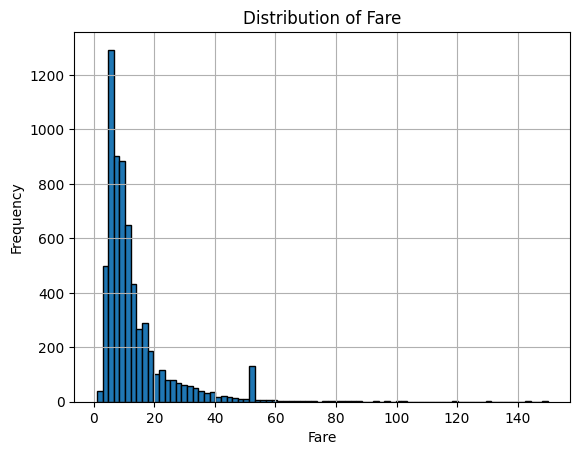

In [7]:
raw['fare'].hist(bins=80, edgecolor='black')
plt.title('Distribution of Fare')
plt.xlabel('Fare')
plt.ylabel('Frequency')
plt.show()

**Вывод.** Сколько строк и столбцов, какие проблемы видны в паспорте (текст вместо чисел, пропуски, странное число разных значений), как распределена цель.

6433 строк и 14 столбцов. Есть некоторое количество пропусков. Есть некая аномалия в fare, ближе к $60 резко возрастает частота поездок

In [8]:
log("загрузка", "первый взгляд, 14 столбцов", len(raw))

---
## 2. Дубли  ·  вместе с разделом 3: 15 баллов

**Что сделать.**

* сколько полных дублей: `raw.duplicated().sum()`;
* если в данных есть номер записи (id), то и повторы по нему: `duplicated(subset=["..."])`;
* посмотреть на несколько дублей глазами (`keep=False`) и решить, что это: ошибка выгрузки, одна запись в нескольких местах или разные настоящие строки;
* записать решение в журнал.

Пример: часть 2 практики, разделы 2.1-2.4.

In [9]:
# сколько дублей, какие они
n_dup = raw.duplicated().sum()
print("Полных дублей:", n_dup, f"({n_dup / len(raw):.1%})")

Полных дублей: 0 (0.0%)


In [10]:
# решение: df = ... ; log(...)
df = raw.drop_duplicates().copy()
log("дубли", "полных дублей нету", len(df))
print(df.shape)

(6433, 14)


**Вывод.** Сколько дублей, что это по смыслу и почему решили удалить или оставить.

Полных дублей 0. Все значения уникальные, так как время и тд разное

---
## 3. Невозможные значения и скрытые пропуски

**Что сделать.**

* написать функцию `check_rules(d)`, которая возвращает таблицу флагов: минимум 3 правила здравого смысла (отрицательная цена, ноль там, где ноль невозможен, возраст 150 лет);
* посмотреть на нарушителей глазами и решить по каждому правилу: удалить, исправить или оставить;
* найти скрытые пропуски: `value_counts()` по текстовым столбцам, `describe()` по числовым. Ищите `unknown`, `Undefined`, `?`, пробел, `999`, нули там, где их не бывает;
* записать решения в журнал.

Пример: часть 2 практики, разделы 2.5-2.7.

In [11]:
def check_rules(d):
    """Таблица флагов: True там, где строка нарушает правило."""
    trip = (pd.to_datetime(d['dropoff']) - pd.to_datetime(d['pickup'])).dt.total_seconds() / 60
    return pd.DataFrame({
        # "название правила": условие,
        "пассажиров 0": d["passengers"] == 0,
        "время поездки 0": trip == 0,
        "расстояние равно 0": d["distance"] == 0,
    })

In [12]:
# сколько нарушений по каждому правилу, нарушители глазами
flags = check_rules(df)
flags.sum()

,0
пассажиров 0,96
время поездки 0,6
расстояние равно 0,51


In [13]:
# скрытые пропуски: value_counts и describe
df['fare'].describe()

,fare
count,6433.000000
mean,13.091073
std,11.551804
min,1.000000
25%,6.500000
50%,9.500000
75%,15.000000
max,150.000000


In [14]:
df.loc[flags["пассажиров 0"], ["pickup", "dropoff", "passengers", "distance", "fare", "total"]].head(10)

,pickup,dropoff,passengers,distance,fare,total
7,2019-03-22 12:47:13,2019-03-22 12:58:17,0,1.4,8.5,11.80
14,2019-03-27 12:13:34,2019-03-27 12:25:48,0,2.9,11.5,14.80
41,2019-03-24 18:42:56,2019-03-24 19:09:00,0,4.5,20.0,23.30
92,2019-03-28 07:05:19,2019-03-28 07:41:14,0,10.6,33.5,40.06
117,2019-03-23 09:39:25,2019-03-23 09:56:45,0,3.6,15.5,22.55
178,2019-03-16 17:27:17,2019-03-16 17:41:03,0,3.5,14.5,15.30
278,2019-03-25 16:23:11,2019-03-25 17:12:18,0,11.8,40.5,52.85
389,2019-03-20 20:38:18,2019-03-20 20:45:26,0,1.1,6.5,9.36
417,2019-03-04 06:44:01,2019-03-04 06:54:26,0,2.1,10.0,14.00
420,2019-03-13 14:37:14,2019-03-13 14:43:12,0,0.7,5.5,10.55


In [15]:
print("средняя цена за поездку с 0 продолжительностью:", round(df.loc[flags["время поездки 0"], "fare"].mean(), 3))
df.loc[flags["время поездки 0"], ["pickup", "dropoff", "passengers", "distance", "fare", "total"]]

средняя цена за поездку с 0 продолжительностью: 17.083


,pickup,dropoff,passengers,distance,fare,total
1690,2019-03-22 06:24:14,2019-03-22 06:24:14,1,0.0,72.0,72.0
5493,2019-03-06 12:14:00,2019-03-06 12:14:00,1,0.0,10.0,10.0
5624,2019-03-11 14:04:50,2019-03-11 14:04:50,1,0.0,2.5,3.3
5638,2019-03-13 12:22:00,2019-03-13 12:22:00,1,0.0,10.0,10.0
6083,2019-03-19 15:34:00,2019-03-19 15:34:00,1,0.0,5.0,5.0
6356,2019-03-01 16:58:23,2019-03-01 16:58:23,1,0.0,3.0,4.8


In [16]:
print("средняя цена за поездку с 0 расстоянием:", round(df.loc[flags["расстояние равно 0"], "fare"].mean(), 3))
df.loc[flags["расстояние равно 0"], ["pickup", "dropoff", "passengers", "distance", "fare", "total"]].head(10)

средняя цена за поездку с 0 расстоянием: 20.475


,pickup,dropoff,passengers,distance,fare,total
42,2019-03-30 23:59:14,2019-03-30 23:59:17,1,0.0,80.0,100.38
120,2019-03-21 17:21:44,2019-03-21 17:21:49,1,0.0,2.5,4.30
622,2019-03-12 19:52:36,2019-03-12 19:52:55,3,0.0,120.0,166.00
670,2019-03-08 04:50:48,2019-03-08 04:51:07,1,0.0,2.5,6.30
970,2019-03-29 00:02:00,2019-03-29 00:02:05,2,0.0,45.0,50.30
1080,2019-03-04 14:17:05,2019-03-04 14:17:13,1,0.0,2.5,3.30
1207,2019-03-08 15:41:20,2019-03-08 15:41:23,1,0.0,2.5,5.80
1482,2019-03-10 20:27:25,2019-03-10 20:28:33,1,0.0,52.0,71.89
1690,2019-03-22 06:24:14,2019-03-22 06:24:14,1,0.0,72.0,72.00
1910,2019-03-25 14:37:56,2019-03-25 14:38:22,1,0.0,2.5,3.31


In [17]:
# решения и журнал
to_drop = ["пассажиров 0", "время поездки 0", "расстояние равно 0"]
bad = check_rules(df)[to_drop].any(axis=1)
print("удаляем строк:", int(bad.sum()))
df = df[~bad].copy()
log("невозможные значения", "удалены: пассажиров 0, время поездки 0 и расстояние равно 0", len(df))
print(df.shape)

удаляем строк: 146
(6287, 14)


**Вывод.** Какие правила, сколько нарушений, что удалили или исправили и почему. Какие скрытые пропуски нашли.

3 правила: пассажиров 0, время поездки 0 и расстояние равно 0
пассажиров 0: 96
время поездки 0: 6
расстояние равно 0: 51

Удалил эти строки, вышло 146 строк. Скрытых пропусков нету

---
## 4. Пропуски  ·  20 баллов

**Что сделать.**

* для каждого столбца с пропусками сравнить цель у строк с пропуском и без: `df.groupby(df[col].isna())[TARGET].mean()`;
* решить, что значит пропуск: «не знаем» или «нет»;
* заполнить: «нет» по смыслу (0, «нет»), «не знаем» медианой, самым частым или категорией `Unknown`; если пропуск говорит о строке, сначала флаг; если пропусков больше половины, флаг и удалить столбец;
* заполнить таблицу решений ниже и записать решения в журнал.

По желанию, без баллов: проверить способ заполнения на известных значениях, как в разделе 3.4 практики.

Пример: часть 3 практики.

In [18]:
# где пропуски и сколько
missing = df.isna().sum()
missing = missing[missing > 0]
pd.DataFrame({"пропусков": missing, "доля, %": (missing / len(df) * 100).round(1)})

,пропусков,"доля, %"
payment,33,0.5
pickup_zone,15,0.2
dropoff_zone,30,0.5
pickup_borough,15,0.2
dropoff_borough,30,0.5


In [19]:
# пропуск как информация: цель у строк с пропуском и без
print("Общее количество пустых строк:", len(df[df.isna().any(axis=1)]))
for col in ["payment", "pickup_zone", "dropoff_zone", "pickup_borough", "dropoff_borough"]:
    rate = df.groupby(df[col].isna())["fare"].mean()
    print(f"{col:15} заполнено: {rate[False]:.3f}   пропуск: {rate[True]:.3f}")

Общее количество пустых строк: 67
payment         заполнено: 13.049   пропуск: 10.530
pickup_zone     заполнено: 13.033   пропуск: 14.333
dropoff_zone    заполнено: 12.876   пропуск: 46.333
pickup_borough  заполнено: 13.033   пропуск: 14.333
dropoff_borough заполнено: 12.876   пропуск: 46.333


In [20]:
cols = ["pickup_zone", "dropoff_zone", "pickup_borough", "dropoff_borough"]
na_rows = df.loc[df[cols].isna().any(axis=1), cols]
print("Количество пустых строк локаций:", len(na_rows))
na_rows.head(10)

Количество пустых строк локаций: 35


,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
606,NaN,Upper East Side South,NaN,Manhattan
671,NaN,Lincoln Square East,NaN,Manhattan
711,Midtown East,NaN,Manhattan,NaN
712,NaN,West Chelsea/Hudson Yards,NaN,Manhattan
739,Upper East Side South,NaN,Manhattan,NaN
1108,NaN,NaN,NaN,NaN
1112,Times Sq/Theatre District,NaN,Manhattan,NaN
1230,Yorkville East,NaN,Manhattan,NaN
1787,Manhattan Valley,NaN,Manhattan,NaN
1961,NaN,Garment District,NaN,Manhattan


In [21]:
df['payment'].value_counts(dropna=False)

,count
payment,
credit card,4478
cash,1776
NaN,33


In [22]:
# заполнение и журнал
location_cols = ["pickup_borough", "dropoff_borough", "pickup_zone", "dropoff_zone"]
df["payment"] = df["payment"].fillna(df["payment"].mode()[0])
df[location_cols] = df[location_cols].fillna("Unknown")

log("пропуски: payment", "заполнил самым часто встречающимся значение credit card, так как разница в fare минимальная", len(df))
log("пропуски: pickup_zone", f"pickup_zone: пропуски заполнены Unknown, для единообразия с dropoff", len(df))
log("пропуски: dropoff_zone", f"dropoff_zone: пропуски заполнены Unknown, так как разница в fare существенная", len(df))
log("пропуски: pickup_borough", f"pickup_borough: пропуски заполнены Unknown, для единообразия с dropoff", len(df))
log("пропуски: dropoff_borough", f"dropoff_borough: пропуски Unknown, так как разница в fare существенная", len(df))

In [23]:
df.isna().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,0


| столбец | пропусков | «не знаем» или «нет» | что делаем | почему |
|---|---|---|---|---|
| payment | 33 | не знаем | заполнил credit card | самое популярное значение |
| pickup_zone | 15 | не знаем | заполнил Unknown | для единообразия с dropoff |
| dropoff_zone | 30 | не знаем | заполнил Unknown | отдельная категория, так как разница в fare существенная |
| pickup_borough | 15 | не знаем | заполнил Unknown | для единообразия с dropoff |
| dropoff_borough | 30 | не знаем | заполнил Unknown | отдельная категория, так как разница в fare существенная |

**Вывод.** Главное о пропусках в ваших данных.

---
## 5. Типы и даты  ·  вместе с разделом 6: 15 баллов

**Что сделать.**

* числа, записанные текстом, превратить в числа: `pd.to_numeric(s, errors="coerce")`, и посмотреть, что попало в пропуски;
* текст с единицами («76%», «SR 1,385», «1800-2200») разобрать: `str.replace`, `str.extract`;
* даты превратить в даты: `pd.to_datetime`, и достать из них признаки: месяц, день недели, час, разницу дат;
* показать `dtypes` после исправлений.

Если в ваших данных нет ни дат, ни чисел текстом, напишите это в выводе: так тоже бывает.

Пример: часть 4 практики, разделы 4.1-4.3.

In [24]:
print(df.dtypes)

pickup              object
dropoff             object
passengers           int64
distance           float64
fare               float64
tip                float64
tolls              float64
total              float64
color               object
payment             object
pickup_zone         object
dropoff_zone        object
pickup_borough      object
dropoff_borough     object
dtype: object


In [25]:
# числа текстом

In [26]:
# даты
df["pickup"] = pd.to_datetime(df["pickup"])
df["dropoff"] = pd.to_datetime(df["dropoff"])

df["pickup_hour"] = df["pickup"].dt.hour
df["pickup_month"] = df["pickup"].dt.month
df["pickup_weekday"] = df["pickup"].dt.day_of_week

df["dropoff_hour"] = df["dropoff"].dt.hour
df["dropoff_month"] = df["dropoff"].dt.month
df["dropoff_weekday"] = df["dropoff"].dt.day_of_week

df["duration_min"] = round((df["dropoff"] - df["pickup"]).dt.total_seconds() / 60, 2)

In [27]:
print(df[["pickup_month", "pickup_weekday", "pickup_hour", "dropoff_month", "dropoff_weekday", "dropoff_hour", "duration_min"]].head(10))

    pickup_month  pickup_weekday  pickup_hour  dropoff_month  dropoff_weekday  dropoff_hour  duration_min
0              3               5           20              3                5            20          6.25
1              3               0           16              3                0            16          7.08
2              3               2           17              3                2            18          7.40
3              3               6            1              3                6             1         25.87
4              3               5           13              3                5            13          9.53
5              3               0           10              3                0            10         10.13
6              3               1           21              3                1            21          9.97
8              3               5           11              3                5            12         17.40
9              3               4           16 

In [28]:
print("медиана:", round(df["duration_min"].median(), 2))
print("максимум:", round(df["duration_min"].max(), 2))

медиана: 10.95
максимум: 107.67


In [29]:
print(df.dtypes)
log("Типы и даты: переписал", "переписал: pickup и dropoff в формате datetime", len(df))
log("Типы и даты: создал", "создал: месяц, день недели, час, продолжительность поездки в минутах", len(df))

pickup             datetime64[ns]
dropoff            datetime64[ns]
passengers                  int64
distance                  float64
fare                      float64
tip                       float64
tolls                     float64
total                     float64
color                      object
payment                    object
pickup_zone                object
dropoff_zone               object
pickup_borough             object
dropoff_borough            object
pickup_hour                 int32
pickup_month                int32
pickup_weekday              int32
dropoff_hour                int32
dropoff_month               int32
dropoff_weekday             int32
duration_min              float64
dtype: object


**Вывод.** Что было записано не так и как исправили.

Все числовые признаки записаны как числа

Признаки pickup и dropoff были записаны как string, переписал их в формате datetime. Также из них создал новые признаки: месяц, день недели, час, продолжительность поездки в минутах

---
## 6. Выбросы

**Что сделать.**

* для главных числовых столбцов найти кандидатов в выбросы: граница IQR или процентили (`quantile(0.999)`);
* по каждому решить: ошибка (удалить или исправить) или редкость (оставить, обрезать `clip`, сжать `np.log1p`);
* для длинного хвоста показать гистограммы до и после логарифма;
* записать решения в журнал.

Пример: часть 4 практики, разделы 4.4-4.6.

In [30]:
# кандидаты в выбросы
df.describe()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,pickup_hour,pickup_month,pickup_weekday,dropoff_hour,dropoff_month,dropoff_weekday,duration_min
count,6287,6287,6287.000000,6287.000000,6287.000000,6287.000000,6287.000000,6287.000000,6287.000000,6287.000000,6287.000000,6287.000000,6287.000000,6287.000000,6287.000000
mean,2019-03-16 08:20:36.931127808,2019-03-16 08:35:02.858437888,1.565134,3.049652,13.035815,1.968032,0.319408,18.456610,13.874503,2.999841,3.165421,13.916176,3.000000,3.167807,14.432109
min,2019-02-28 23:29:03,2019-02-28 23:32:35,1.000000,0.010000,1.000000,0.000000,0.000000,1.300000,0.000000,2.000000,0.000000,0.000000,2.000000,0.000000,0.030000
25%,2019-03-08 15:46:15,2019-03-08 16:07:07,1.000000,1.000000,6.500000,0.000000,0.000000,10.800000,10.000000,3.000000,2.000000,10.000000,3.000000,2.000000,6.580000
50%,2019-03-15 21:33:57,2019-03-15 21:51:22,1.000000,1.660000,9.500000,1.700000,0.000000,14.160000,15.000000,3.000000,3.000000,15.000000,3.000000,3.000000,10.950000
75%,2019-03-23 17:15:15.500000,2019-03-23 17:29:35,2.000000,3.250000,15.000000,2.760000,0.000000,20.300000,19.000000,3.000000,5.000000,19.000000,3.000000,5.000000,18.550000
max,2019-03-31 23:43:45,2019-04-01 00:13:58,6.000000,36.700000,150.000000,23.190000,24.020000,174.820000,23.000000,3.000000,6.000000,23.000000,4.000000,6.000000,107.670000
std,NaN,NaN,1.200082,3.837271,11.308260,2.384374,1.400476,13.492901,6.075147,0.012612,1.913745,6.150861,0.017837,1.916237,11.591356


In [31]:
num_cols = ['distance', 'fare', 'tip', 'tolls', 'total', 'duration_min']

for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    upper_iqr = q3 + 1.5 * iqr
    q999 = df[col].quantile(0.999)
    print(f"{col}: верхняя граница IQR = {upper_iqr:.2f}, квантиль 0.999 = {q999:.2f}, max = {df[col].max():.2f}")

distance: верхняя граница IQR = 6.62, квантиль 0.999 = 27.80, max = 36.70
fare: верхняя граница IQR = 27.75, квантиль 0.999 = 91.78, max = 150.00
tip: верхняя граница IQR = 6.90, квантиль 0.999 = 16.36, max = 23.19
tolls: верхняя граница IQR = 0.00, квантиль 0.999 = 11.52, max = 24.02
total: верхняя граница IQR = 34.55, квантиль 0.999 = 105.25, max = 174.82
duration_min: верхняя граница IQR = 36.51, квантиль 0.999 = 75.55, max = 107.67


In [32]:
print("Топ-5 самых дорогих поездок:")
print(df.sort_values(by='fare', ascending=False)[['pickup', 'dropoff', 'distance', 'fare', 'tolls', 'total']].head(5))

Топ-5 самых дорогих поездок:
                  pickup             dropoff  distance   fare  tolls   total
5648 2019-03-19 14:21:35 2019-03-19 15:51:28     33.46  150.0  18.90  169.70
5364 2019-03-17 16:59:17 2019-03-17 18:04:08     36.70  150.0  24.02  174.82
4050 2019-03-13 14:05:19 2019-03-13 15:01:16     33.76  143.5   0.00  144.30
2231 2019-03-11 10:17:31 2019-03-11 11:03:55     26.35  130.0   5.76  136.56
4815 2019-03-08 11:25:08 2019-03-08 11:50:30     10.36  100.0   0.00  123.36


In [33]:
short_trips = df[(df['duration_min'] < 0.5) | (df['distance'] < 0.05)]
print(f"Подозрительно коротких поездок: {len(short_trips)}")
print(short_trips[['distance', 'duration_min', 'fare', 'total']])

Подозрительно коротких поездок: 18
      distance  duration_min  fare  total
88        0.07          0.30   2.5   3.80
400       0.90          0.13   2.5   5.80
458       0.02          0.23   2.5   6.30
491       1.60          0.10   2.5   5.80
739       0.03          0.07   2.5   3.80
2150      0.11          0.45  52.0  60.30
3241      0.34          0.03  65.0  78.36
3336      1.70          0.32  14.0  16.30
3571      0.81          0.15  66.0  66.80
4127      0.04          0.15   2.5   3.80
4358      0.01          0.22   2.5   4.30
4562      0.10          0.15  20.0  20.80
4746      1.30          0.23   2.5   5.80
4836      0.02          0.07   2.5   3.30
5284      1.70          0.15   2.5   5.80
5490      0.02          0.22   2.5   3.30
5821      0.10          0.20   2.5   4.30
6089     10.10          0.30  12.0  12.00


In [34]:
df.drop(short_trips.index, inplace=True)
df.reset_index(drop=True, inplace=True)

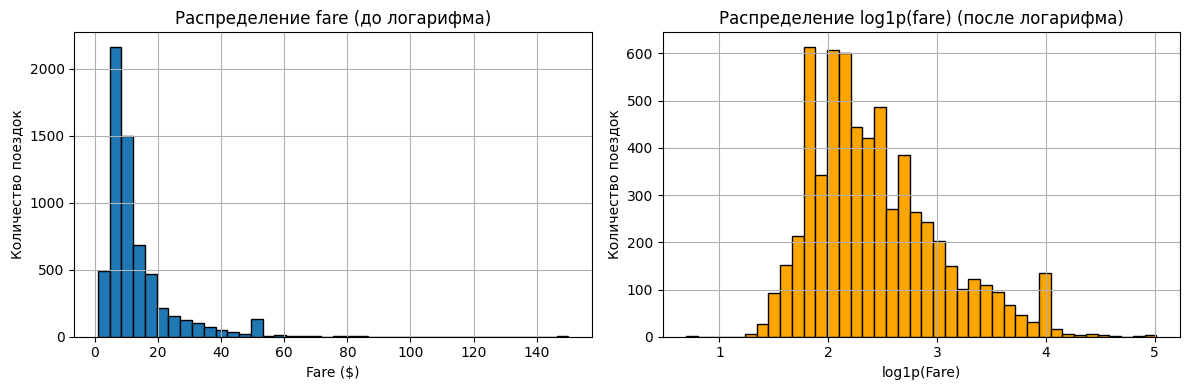

In [35]:
# Гистограммы до и после логарифмирования (np.log1p)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Первый график
df['fare'].hist(bins=40, ax=axes[0], edgecolor='black')
axes[0].set_title('Распределение fare (до логарифма)')
axes[0].set_xlabel('Fare ($)')
axes[0].set_ylabel('Количество поездок')

# Второй график
np.log1p(df['fare']).hist(bins=40, ax=axes[1], edgecolor='black', color='orange')
axes[1].set_title('Распределение log1p(fare) (после логарифма)')
axes[1].set_xlabel('log1p(Fare)')
axes[1].set_ylabel('Количество поездок')

plt.tight_layout()
plt.show()

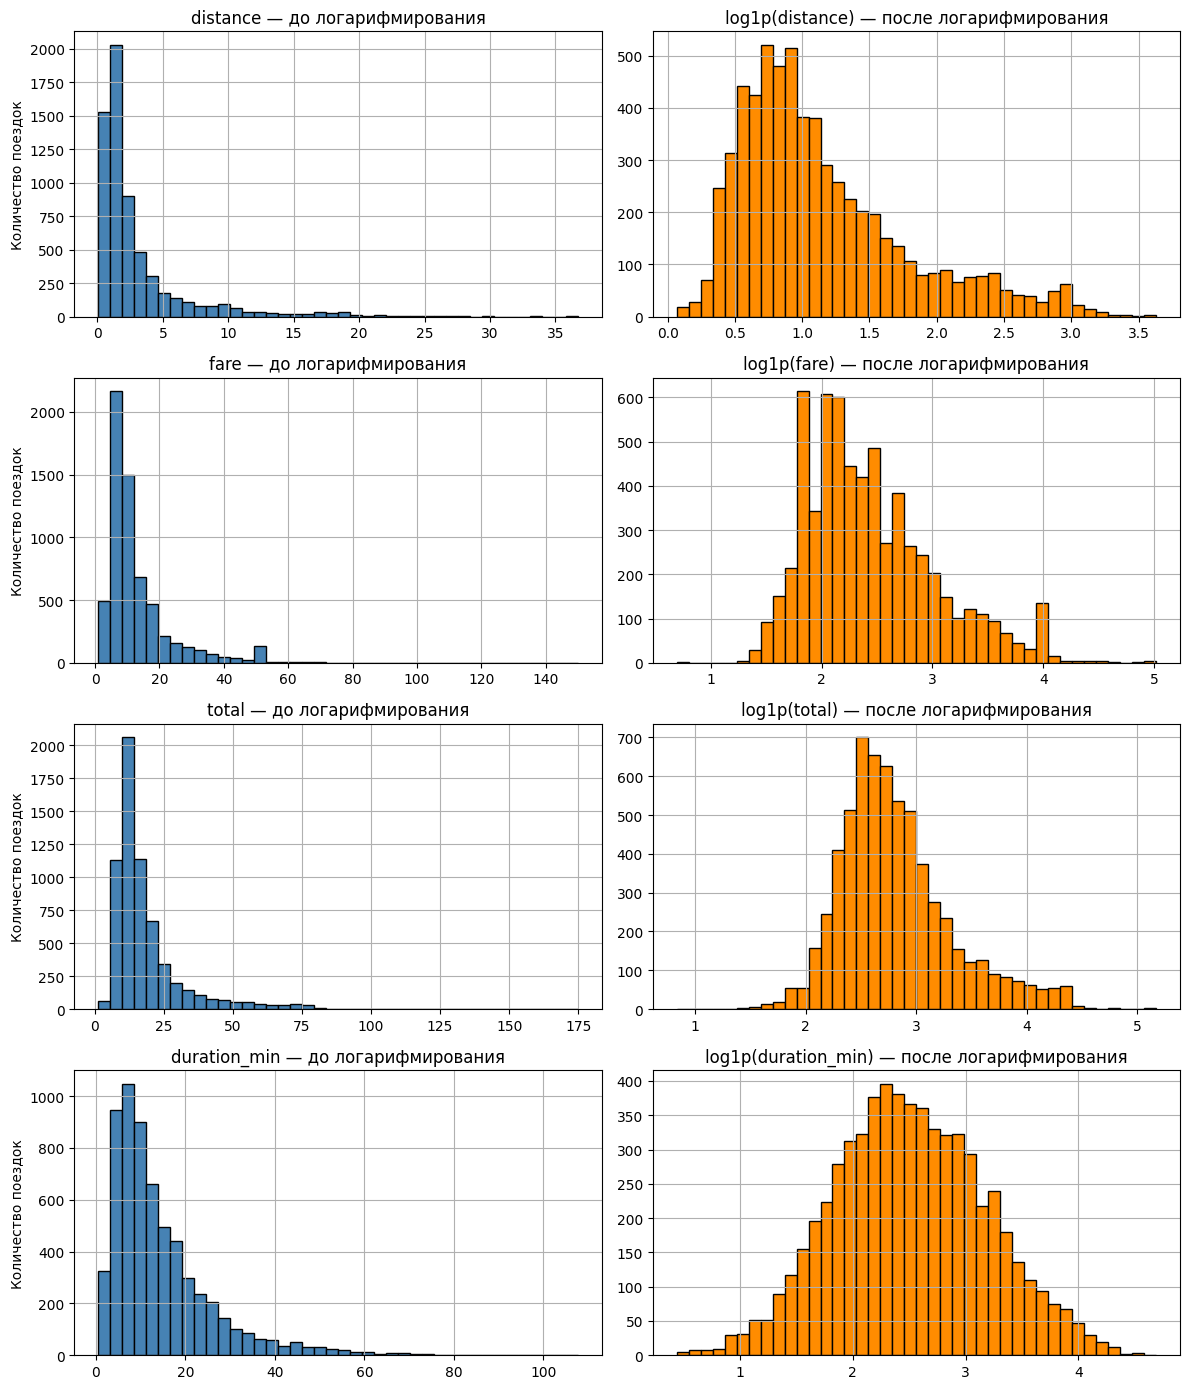

In [36]:
tail_cols = ['distance', 'fare', 'total', 'duration_min']
fig, axes = plt.subplots(len(tail_cols), 2, figsize=(12, 14))

for i, col in enumerate(tail_cols):
    # До логарифмирования
    df[col].hist(bins=40, ax=axes[i, 0], edgecolor='black', color='steelblue')
    axes[i, 0].set_title(f'{col} — до логарифмирования')
    axes[i, 0].set_ylabel('Количество поездок')

    # После np.log1p
    np.log1p(df[col]).hist(bins=40, ax=axes[i, 1], edgecolor='black', color='darkorange')
    axes[i, 1].set_title(f'log1p({col}) — после логарифмирования')

plt.tight_layout()
plt.show()

In [37]:
log("Выбросы: Нижняя граница", "удалены 18 записей с ошибками", len(df))
log("Выбросы: Верхняя граница", "самые дорогие поездки оставлены так как являются редкими дальними поездками", len(df))
log("Выбросы: Трансформация", "редкие дальние поездки решено оставить", len(df))

**Вывод.** Какие выбросы нашли, что из них ошибки, а что настоящие редкости.

1. Нижняя граница (duration_min < 0.5 мин или distance < 0.05 миль):  18 записей с ошибками (например, поездка длиной 1.8 секунды с тарифом $65.0 или расстояние 10.1 мили за 18 секунд). Эти строки удалены как явные ошибки.

2. Верхняя граница (distance, fare, total, duration_min, tip, tolls): Значения выше границы Q₃ + 1.5 ⋅ IQR и квантиля 0.999. Самые дорогие поездки (fare до $150) имеют большое расстояние (33–36.7 миль) и длительность (~60–90 минут), являются настоящими редкими дальними поездками.

3. Трансформация: Редкие дальние поездки решено оставить (не удалять и не обрезать через clip), а правостороннюю асимметрию («длинный хвост») сгладить с помощью логарифмирования np.log1p(), что подтверждено гистограммами до и после преобразования.

---
## 7. EDA: пять графиков  ·  20 баллов

**Что сделать.** Минимум 5 графиков. У каждого заголовок-вывод (не «lead_time и is_canceled», а «Чем раньше бронь, тем чаще отмена»), подписи осей с единицами и 1-3 предложения под графиком.

| график | на какой вопрос отвечает |
|---|---|
| распределение цели | какая доля классов или как распределено число |
| цель по 3-4 сильным признакам | что сильнее всего связано с целью |
| цель по времени или по группам | меняется ли картина по сезонам, городам, категориям |
| находка | что удивило: парадокс или подозрительно идеальный признак |

`target_plot(df, группы, TARGET, "заголовок-вывод", "подпись оси x")` рисует цель по группам. Числовой признак сначала разбейте на интервалы: `pd.cut(df["столбец"], [границы])`. Для двух числовых столбцов подойдёт `plt.scatter`.

Пример: часть 6 практики.

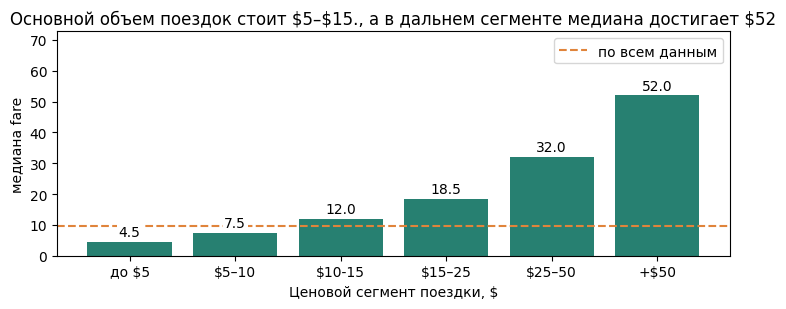

,median,size
fare,,
до $5,4.5,802
$5–10,7.5,2720
$10-15,12.0,1242
$15–25,18.5,836
$25–50,32.0,496
+$50,52.0,159


In [38]:
# график 1
fare_bins = pd.cut(df[TARGET],bins=[0, 5, 10, 15, 25, 50, 70],labels=["до $5", "$5–10", "$10-15", "$15–25", "$25–50", "+$50"])
target_plot(df,fare_bins,TARGET,"Основной объем поездок стоит $5–$15., а в дальнем сегменте медиана достигает $52","Ценовой сегмент поездки, $")

**Что видно на графике 1.**

Основная масса заказов приходится на бюджетные поездки с медианным тарифом 7.5 дол. в сегменте 5–10 дол. и 12.0 дол. в сегменте 10–15 дол. В самом дорогом сегменте (свыше 50 дол.) медианный чек достигает 52.0 дол., что в пять раз выше общей медианы по датасету.

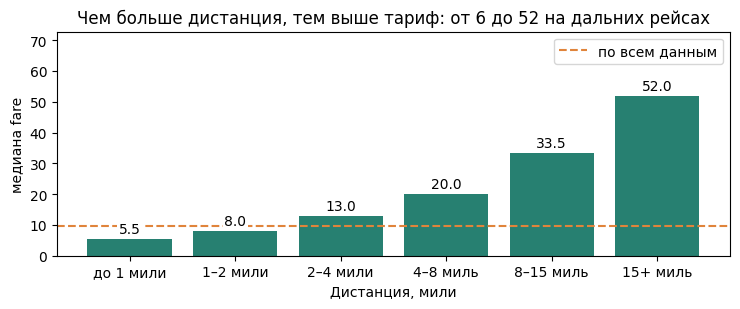

,median,size
distance,,
до 1 мили,5.5,1659
1–2 мили,8.0,2023
2–4 мили,13.0,1371
4–8 миль,20.0,649
8–15 миль,33.5,385
15+ миль,52.0,182


In [39]:
# график 2
dist_bins = pd.cut(df["distance"],bins=[0, 1, 2, 4, 8, 15, 40],labels=["до 1 мили", "1–2 мили", "2–4 мили", "4–8 миль", "8–15 миль", "15+ миль"])
target_plot(df, dist_bins, TARGET, "Чем больше дистанция, тем выше тариф: от 6 до 52 на дальних рейсах","Дистанция, мили")

**Что видно на графике 2.**

Дистанция это самый сильный фактор формирования тарифа. Медианный тариф  растет с 5.5 дол. на коротких поездках (до 1 мили) до 52 дол. на рейсах свыше 15 миль. Дистанция имеет прямую связь с таксометром и станет ключевым признаком для модели.

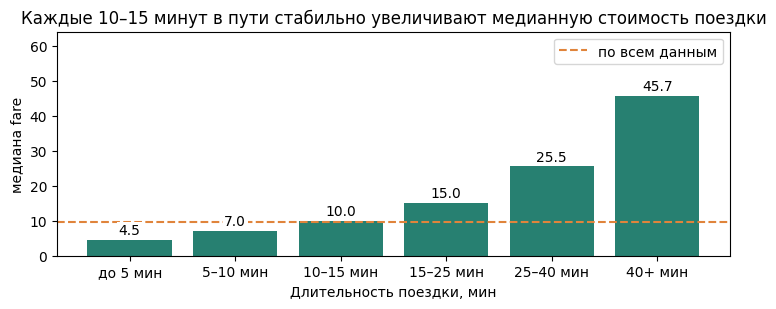

,median,size
duration_min,,
до 5 мин,4.50,913
5–10 мин,7.00,1924
10–15 мин,10.00,1249
15–25 мин,15.00,1304
25–40 мин,25.50,606
40+ мин,45.71,273


In [40]:
# график 3
dur_bins = pd.cut(df["duration_min"],bins=[0, 5, 10, 15, 25, 40, 120],labels=["до 5 мин", "5–10 мин", "10–15 мин", "15–25 мин", "25–40 мин", "40+ мин"])
target_plot(df, dur_bins, TARGET,"Каждые 10–15 минут в пути стабильно увеличивают медианную стоимость поездки","Длительность поездки, мин")

**Что видно на графике 3.**

Медианная стоимость поездки увеличивается вместе с временем в пути. От 4.5 дол. для поездок короче 5 минут до 45.7 дол. для поездок дольше 40 минут. Таксометр учитывает не только дистанцию, но и время ожидания в пробках, поэтому duration_min дополняет distance.

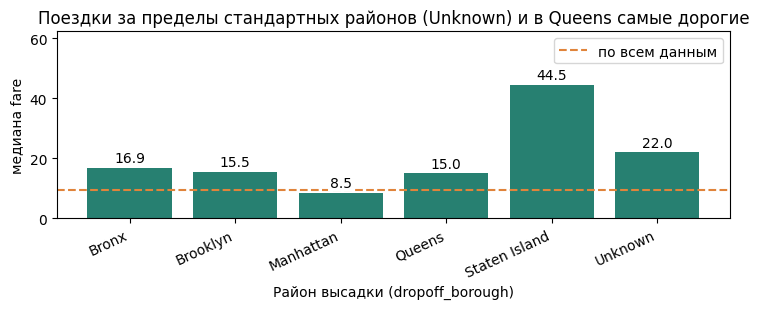

,median,size
dropoff_borough,,
Bronx,16.88,136
Brooklyn,15.50,489
Manhattan,8.50,5098
Queens,15.00,517
Staten Island,44.50,2
Unknown,22.00,27


In [41]:
# график 4
target_plot(df, "dropoff_borough", TARGET, "Поездки за пределы стандартных районов (Unknown) и в Queens самые дорогие", "Район высадки (dropoff_borough)")


**Что видно на графике 4.**

Самые дешевые поездки совершаются внутри Манхэттена (медиана 8.5 дол.), так как там преобладают короткие перемещения. Самые дорогие направления это район Staten Island (медиана 44.5 дол.) и выделенная категория Unknown (медиана 21.5 дол.).

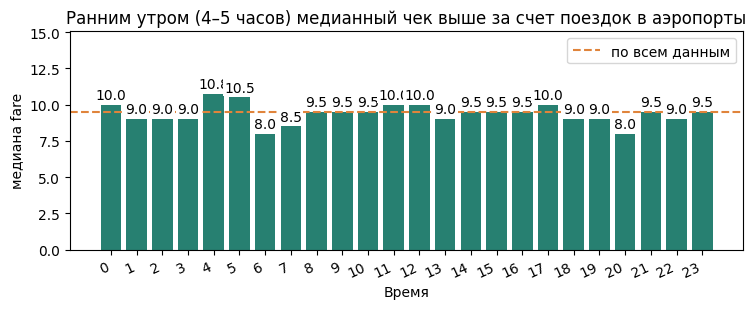

,median,size
pickup_hour,,
0,10.00,197
1,9.00,107
2,9.00,101
3,9.00,66
4,10.75,56
5,10.50,49
6,8.00,135
7,8.50,211
8,9.50,310


In [42]:
# график 5
target_plot(df, "pickup_hour", TARGET, "Ранним утром (4–5 часов) медианный чек выше за счет поездок в аэропорты","Время")

**Что видно на графике 5.**

В течение суток медианная стоимость поездки остается достаточно стабильной на уровне 9–10 дол. (около пунктирной линии), но в 4 утра достигает суточного максимума в 10.8 дол. (при 56 поездок). Ночью и ранним утром такси чаще вызывают для поездок в аэропорты. Самые дешевые медианные поездки фиксируются в 6 утра и 20 вечера (8 дол.).

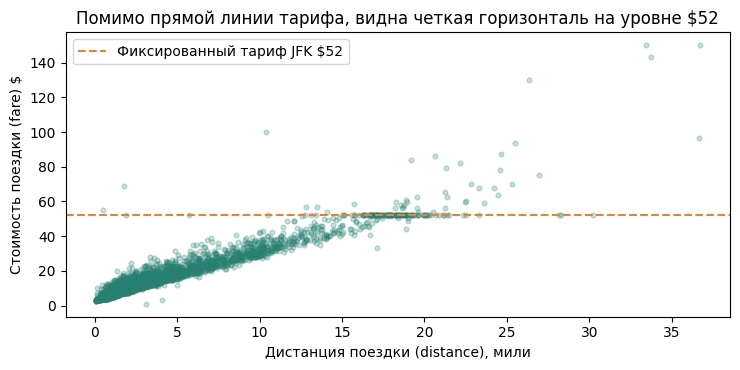

In [43]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.scatter(df["distance"], df["fare"], alpha=0.25, s=12, color=TEAL)
ax.axhline(52, color=ORANGE, ls="--", lw=1.5, label="Фиксированный тариф JFK $52")
ax.set_title("Помимо прямой линии тарифа, видна четкая горизонталь на уровне $52")
ax.set_xlabel("Дистанция поездки (distance), мили")
ax.set_ylabel("Стоимость поездки (fare) $")
ax.legend()
plt.tight_layout()
plt.show()

**Что видно на графике 6.**

На диаграмме видна жесткая линейная зависимость между дистанцией и ценой, но при этом на уровне 52 $ проходит ровная горизонтальная полоса для поездок длиной 15–22 мили. Это официальный фиксированный тариф такси Нью-Йорка на маршруте из аэропорта JFK в Манхэттен. Также заметны редкие точки выше основной линии, это поездки с долгим простоем в пробках.

**Вывод по EDA.** 3-5 главных находок с числами.

1. Сильная асимметрия с тарифом поездки: Общая медиана стоимости поездки составляет 9.5 дол., и более половины заказов (3 964 поездки) сосредоточены в бюджетных сегментах от 5 до 15 долл. (с медианами 7.5 дол. в сегменте 5–10 долл. и 12.0 дол. в сегменте 10–15 дол.).
2. Главные драйверы цены дистанция (distance) и время в пути (duration_min): Оба признака демонстрируют строгий рост целевой переменной.
3. Самые дешевые поездки совершаются внутри Манхэттена (медиана 8.5 дол.), тогда как поездки в удаленный Staten Island показывают максимальную медиану в 44.5 дол. Выделение пропусков в отдельную категорию Unknown полностью оправдало себя: их медианный тариф составил 21.5 дол. (а средний до очистки превышал 43–46 дол.), что в 2.5 раза выше поездок по Манхэттену.

---
## 8. Функция clean, сторожа и журнал  ·  10 баллов

**Что сделать.**

* собрать все решения разделов 2-6 в одну функцию `clean(raw_table)`: на входе сырая таблица, на выходе чистая;
* проверить, что `clean(raw)` даёт ту же таблицу, что пошаговая очистка;
* сторожа: `assert` на главные правила, например «нет пропусков», «нет невозможных значений»;
* показать журнал: `show_journal()`;
* сохранить чистые данные: `clean_df.to_csv("data/<имя>_clean.csv", index=False)`.

Пример: часть 9 практики, разделы 9.1-9.4.

In [44]:
def clean(raw_table):
    """Сырая таблица на входе, очищенная на выходе."""
    d = raw_table.drop_duplicates().copy()
    # ваши шаги из разделов 2-6
    d = d[~check_rules(d)[to_drop].any(axis=1)].copy()

    location_cols = ["pickup_borough", "dropoff_borough", "pickup_zone", "dropoff_zone"]
    d["payment"] = d["payment"].fillna(d["payment"].mode()[0])
    d[location_cols] = d[location_cols].fillna("Unknown")

    d["pickup"] = pd.to_datetime(d["pickup"])
    d["dropoff"] = pd.to_datetime(d["dropoff"])

    d["pickup_hour"] = d["pickup"].dt.hour
    d["pickup_month"] = d["pickup"].dt.month
    d["pickup_weekday"] = d["pickup"].dt.day_of_week

    d["dropoff_hour"] = d["dropoff"].dt.hour
    d["dropoff_month"] = d["dropoff"].dt.month
    d["dropoff_weekday"] = d["dropoff"].dt.day_of_week

    d["duration_min"] = round((d["dropoff"] - d["pickup"]).dt.total_seconds() / 60, 2)

    short_trips = d[(d['duration_min'] < 0.5) | (d['distance'] < 0.05)]
    d.drop(short_trips.index, inplace=True)
    d.reset_index(drop=True, inplace=True)

    return d

In [45]:
# clean_df = clean(raw); сравнение с пошаговой очисткой; сторожа assert
clean_df = clean(raw)
print(clean_df.shape, df.shape)
print("совпадает с пошаговой очисткой:", clean_df.equals(df))

(6269, 21) (6269, 21)
совпадает с пошаговой очисткой: True


In [46]:
def check_clean(d):
    """Сторожа: тетрадь остановится, если очистка что-то пропустила."""
    assert not check_rules(d)[to_drop].any().any(), "остались невозможные значения"
    assert d.notna().all().all(), "остались пропуски"
    print("очистка прошла все проверки")


check_clean(clean_df)

очистка прошла все проверки


In [47]:
show_journal()

,решение,строк
загрузка,"первый взгляд, 14 столбцов",6433
дубли,полных дублей нету,6433
невозможные значения,"удалены: пассажиров 0, время поездки 0 и расст...",6287
пропуски: payment,заполнил самым часто встречающимся значение cr...,6287
пропуски: pickup_zone,"pickup_zone: пропуски заполнены Unknown, для е...",6287
пропуски: dropoff_zone,"dropoff_zone: пропуски заполнены Unknown, так ...",6287
пропуски: pickup_borough,"pickup_borough: пропуски заполнены Unknown, дл...",6287
пропуски: dropoff_borough,"dropoff_borough: пропуски Unknown, так как раз...",6287
Типы и даты: переписал,переписал: pickup и dropoff в формате datetime,6287
Типы и даты: создал,"создал: месяц, день недели, час, продолжительн...",6287


In [48]:
Path("data").mkdir(exist_ok=True)
clean_df.to_csv("data/taxi_clean.csv", index=False)

---
## 9. Самопроверка и репозиторий  ·  10 баллов

**Самопроверка.** Уберите `#` и запустите. Всё должно быть `OK`, а если где-то `НЕТ` по делу (например, дубли появились после обрезки выбросов, как в части 9 практики), объясните это в выводе.

In [49]:
selfcheck(raw, clean_df, TARGET)

OK   цель есть в чистой таблице
OK   цель без пропусков
OK   цель числом: класс 0 и 1 или число
OK   в чистой таблице нет пропусков
OK   полных дублей нет (если есть, объясните в выводе)
OK   осталось больше половины строк
OK   в журнале минимум 5 решений
строк: было 6433, стало 6269; столбцов: было 14, стало 21


**Репозиторий.**

1. github.com, справа вверху «+», затем «New repository». Имя, например, `midterm-telco`, видимость **Public**, галочку README не ставить.
2. «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь проходит без ошибок. Сохраните её.
3. Скачайте тетрадь: «Файл», затем «Скачать», затем «Скачать .ipynb», имя `project.ipynb`. Скачайте чистый CSV из папки `data` на панели файлов слева.
4. На странице репозитория ссылка «uploading an existing file», перетащите `project.ipynb` и папку `data`, «Commit changes» с подписью «этап 1».
5. Откройте ссылку в режиме инкогнито: тетрадь открывается, графики видны. Сдайте ссылку в LMS.

README на этапе 1 можно сделать черновым: название проекта и одна строка о задаче. Полный README это этап 2.

Пример: часть 9 практики, разделы 9.5-9.6.

---
# Этап 2. Мидтерм, домашка занятия 12

Эти разделы заполняются после занятия 12, в этой же тетради и в том же репозитории. Здесь коротко, что в них будет. Подробности и баллы в ТЗ, примеры в частях 5, 7, 8 и 9 тетради практики занятия 11. Инструменты занятия 12 можно и нужно использовать.

## 10. Новые признаки

Минимум 3 признака из смысла задачи: суммы, доли, флаги, части дат. У каждого одно предложение «зачем». Пример: часть 5, раздел 5.1.

In [50]:
# этап 2

## 11. Категории

Редкие значения в `Other`, флаги через `get_dummies`. Итог: таблица признаков `X` только из чисел, без пропусков. Пример: часть 5, разделы 5.2-5.5.

In [51]:
# этап 2

## 12. Утечка

Таблица «столбец, когда становится известен, берём или нет» для всех подозрительных столбцов. Проверка моделью хотя бы одного подозреваемого: насколько он поднимает качество. Пример: часть 7.

In [52]:
# этап 2

## 13. Baseline

Train и test, пустышка, простая модель на 3-5 признаках, полная модель в `Pipeline`, кросс-валидация на train, test один раз в конце, график-лестница и вывод «модель лучше пустышки на ...». Пример: часть 8.

In [53]:
# этап 2

## 14. Выводы

3-5 пунктов: что узнали о данных, что сработало, что бы сделали дальше.

## 15. README

По шаблону из ТЗ. Журнал и результаты удобно собрать из переменных тетради. Пример: часть 9, раздел 9.4.

In [54]:
# этап 2

## 16. Финальная проверка

`requirements.txt`, «Перезапустить сеанс и выполнить все» без ошибок, тетрадь сохранена с выводами, ссылка открывается в режиме инкогнито. Чек-лист в ТЗ.